Часть 1. EDA

Выберите любой интересующий вас датасет по классификации или регрессии.

Выбрано предсказание Customer Livetime Value (CLV или LTV) - https://www.kaggle.com/pankajjsh06/ibm-watson-marketing-customer-value-data

По выбранному датасету проведите EDA, познакомьтесь с признаками, посмотрите зависимости и т.д.

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

In [41]:
random.seed(42)

In [42]:
df = pd.read_csv('WA_Fn-UseC_-Marketing-Customer-Value-Analysis.csv', encoding='latin1')

In [43]:
df.head()

,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,...,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
0,BU79786,Washington,2763.519279,No,Basic,Bachelor,2/24/11,Employed,F,56274,...,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize
1,QZ44356,Arizona,6979.535903,No,Extended,Bachelor,1/31/11,Unemployed,F,0,...,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize
2,AI49188,Nevada,12887.431650,No,Premium,Bachelor,2/19/11,Employed,F,48767,...,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize
3,WW63253,California,7645.861827,No,Basic,Bachelor,1/20/11,Unemployed,M,0,...,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize
4,HB64268,Washington,2813.692575,No,Basic,Bachelor,2/3/11,Employed,M,43836,...,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize


In [44]:
df.columns

Index(['Customer', 'State', 'Customer Lifetime Value', 'Response', 'Coverage',
       'Education', 'Effective To Date', 'EmploymentStatus', 'Gender',
       'Income', 'Location Code', 'Marital Status', 'Monthly Premium Auto',
       'Months Since Last Claim', 'Months Since Policy Inception',
       'Number of Open Complaints', 'Number of Policies', 'Policy Type',
       'Policy', 'Renew Offer Type', 'Sales Channel', 'Total Claim Amount',
       'Vehicle Class', 'Vehicle Size'],
      dtype='str')

'Customer', 
'State', 
'Customer Lifetime Value', 
'Response', 
'Coverage',
'Education', 
'Effective To Date', 
'EmploymentStatus', 
'Gender',
'Income', 
'Location Code', 
'Marital Status', 
'Monthly Premium Auto',
'Months Since Last Claim', 
'Months Since Policy Inception',
'Number of Open Complaints', 
'Number of Policies', 
'Policy Type',
'Policy', 
'Renew Offer Type', 
'Sales Channel', 
'Total Claim Amount',
'Vehicle Class', 
'Vehicle Size'



In [45]:
df.describe()

,Customer Lifetime Value,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount
count,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000
mean,8004.940475,37657.380009,93.219291,15.097000,48.064594,0.384388,2.966170,434.088794
std,6870.967608,30379.904734,34.407967,10.073257,27.905991,0.910384,2.390182,290.500092
min,1898.007675,0.000000,61.000000,0.000000,0.000000,0.000000,1.000000,0.099007
25%,3994.251794,0.000000,68.000000,6.000000,24.000000,0.000000,1.000000,272.258244
50%,5780.182197,33889.500000,83.000000,14.000000,48.000000,0.000000,2.000000,383.945434
75%,8962.167041,62320.000000,109.000000,23.000000,71.000000,0.000000,4.000000,547.514839
max,83325.381190,99981.000000,298.000000,35.000000,99.000000,5.000000,9.000000,2893.239678


In [46]:
df.isnull().sum()

Customer                         0
State                            0
Customer Lifetime Value          0
Response                         0
Coverage                         0
Education                        0
Effective To Date                0
EmploymentStatus                 0
Gender                           0
Income                           0
Location Code                    0
Marital Status                   0
Monthly Premium Auto             0
Months Since Last Claim          0
Months Since Policy Inception    0
Number of Open Complaints        0
Number of Policies               0
Policy Type                      0
Policy                           0
Renew Offer Type                 0
Sales Channel                    0
Total Claim Amount               0
Vehicle Class                    0
Vehicle Size                     0
dtype: int64

In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9134 entries, 0 to 9133
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Customer                       9134 non-null   str    
 1   State                          9134 non-null   str    
 2   Customer Lifetime Value        9134 non-null   float64
 3   Response                       9134 non-null   str    
 4   Coverage                       9134 non-null   str    
 5   Education                      9134 non-null   str    
 6   Effective To Date              9134 non-null   str    
 7   EmploymentStatus               9134 non-null   str    
 8   Gender                         9134 non-null   str    
 9   Income                         9134 non-null   int64  
 10  Location Code                  9134 non-null   str    
 11  Marital Status                 9134 non-null   str    
 12  Monthly Premium Auto           9134 non-null   int64  
 13 

Пропусков нет

In [48]:
df.nunique()

Customer                         9134
State                               5
Customer Lifetime Value          8041
Response                            2
Coverage                            3
Education                           5
Effective To Date                  59
EmploymentStatus                    5
Gender                              2
Income                           5694
Location Code                       3
Marital Status                      3
Monthly Premium Auto              202
Months Since Last Claim            36
Months Since Policy Inception     100
Number of Open Complaints           6
Number of Policies                  9
Policy Type                         3
Policy                              9
Renew Offer Type                    4
Sales Channel                       4
Total Claim Amount               5106
Vehicle Class                       6
Vehicle Size                        3
dtype: int64

In [49]:
df_num = df.select_dtypes(include=['int64', 'float64'])
df_num.head()

,Customer Lifetime Value,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount
0,2763.519279,56274,69,32,5,0,1,384.811147
1,6979.535903,0,94,13,42,0,8,1131.464935
2,12887.431650,48767,108,18,38,0,2,566.472247
3,7645.861827,0,106,18,65,0,7,529.881344
4,2813.692575,43836,73,12,44,0,1,138.130879


array([[<Axes: title={'center': 'Customer Lifetime Value'}>,
        <Axes: title={'center': 'Income'}>,
        <Axes: title={'center': 'Monthly Premium Auto'}>],
       [<Axes: title={'center': 'Months Since Last Claim'}>,
        <Axes: title={'center': 'Months Since Policy Inception'}>,
        <Axes: title={'center': 'Number of Open Complaints'}>],
       [<Axes: title={'center': 'Number of Policies'}>,
        <Axes: title={'center': 'Total Claim Amount'}>, <Axes: >]],
      dtype=object)

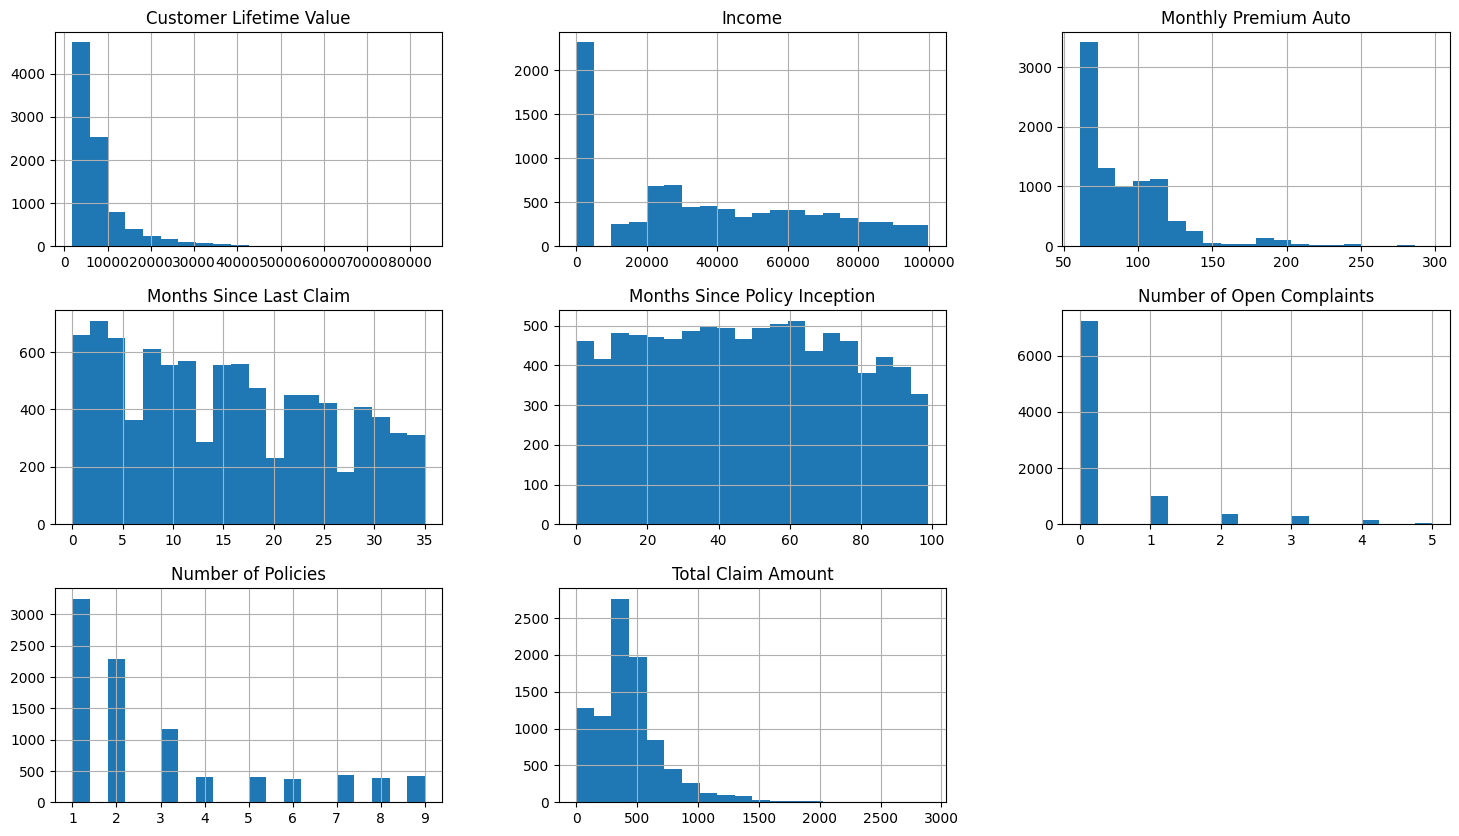

In [50]:
df_num.hist(figsize=(18, 10), bins=20)

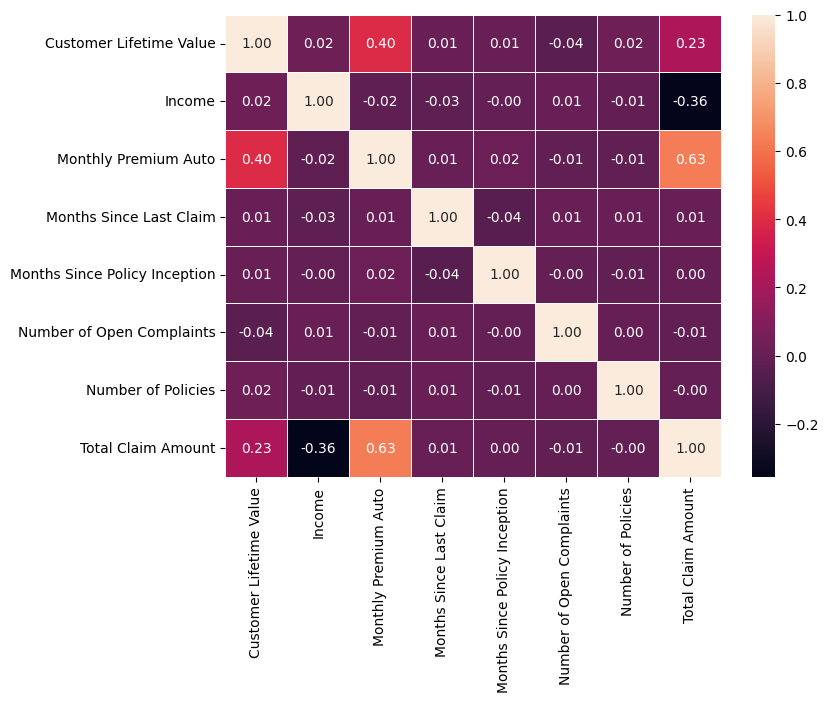

In [51]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_num.corr(), annot=True, cbar=True, linewidths=.5, fmt= '.2f')
plt.show()

In [52]:
df_num.columns

Index(['Customer Lifetime Value', 'Income', 'Monthly Premium Auto',
       'Months Since Last Claim', 'Months Since Policy Inception',
       'Number of Open Complaints', 'Number of Policies',
       'Total Claim Amount'],
      dtype='str')

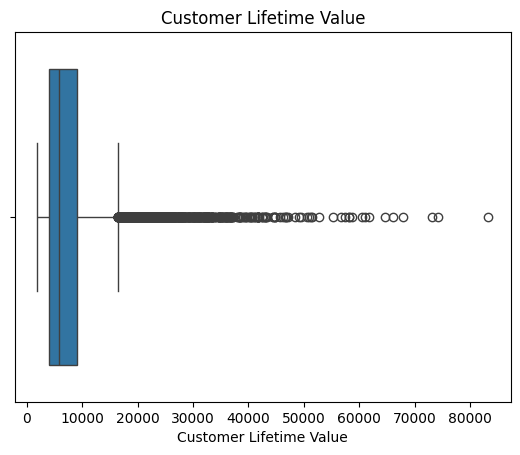

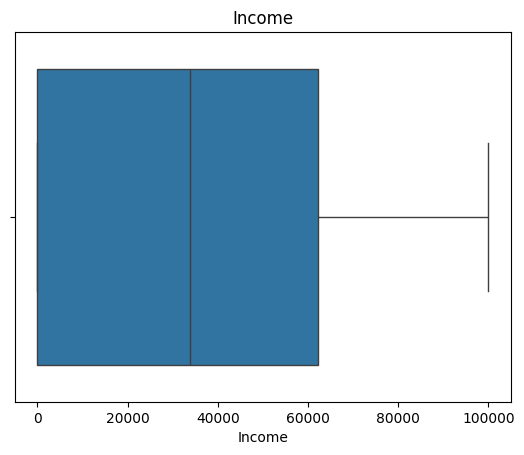

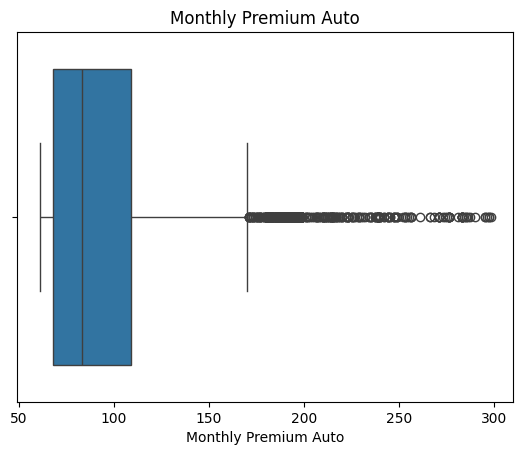

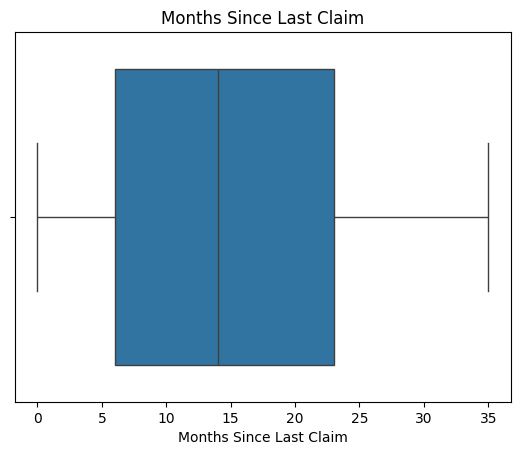

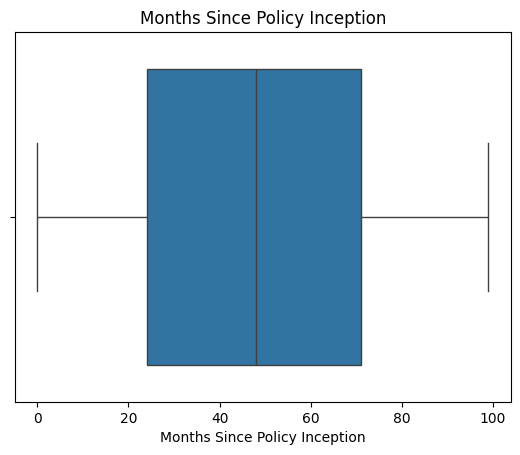

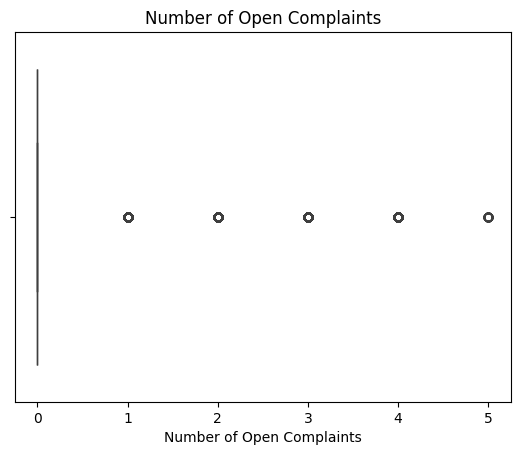

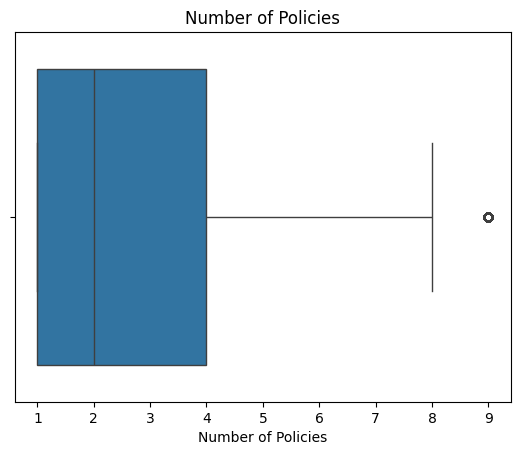

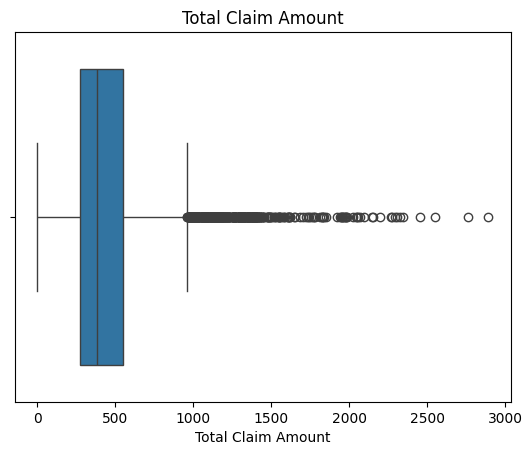

In [53]:
for col in df_num:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

/tmp/ipykernel_13877/272080124.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/tmp/ipykernel_13877/272080124.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/tmp/ipykernel_13877/272080124.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/tmp/ipykernel_13877/272080124.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/tmp/ipykernel_13877/272080124.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/tmp/ipykernel_13877/272080124.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/tmp/ipykernel_13877/272080124.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/tmp/ipykernel_13877/272080124.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/tmp/ipy

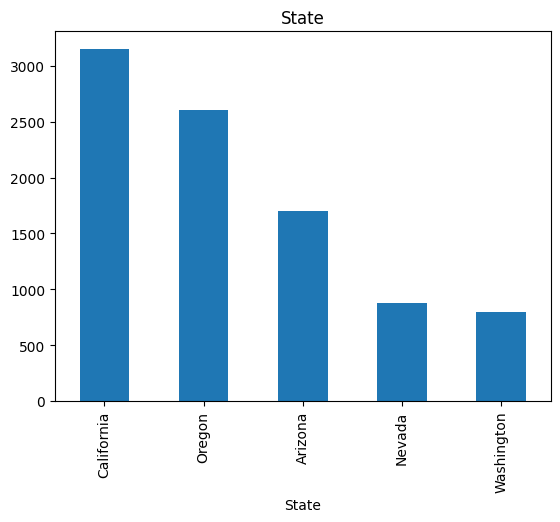

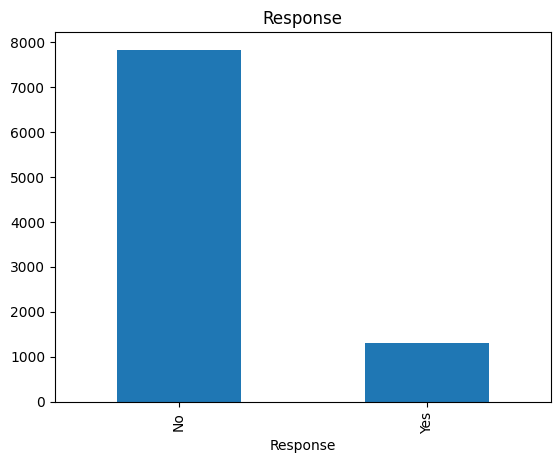

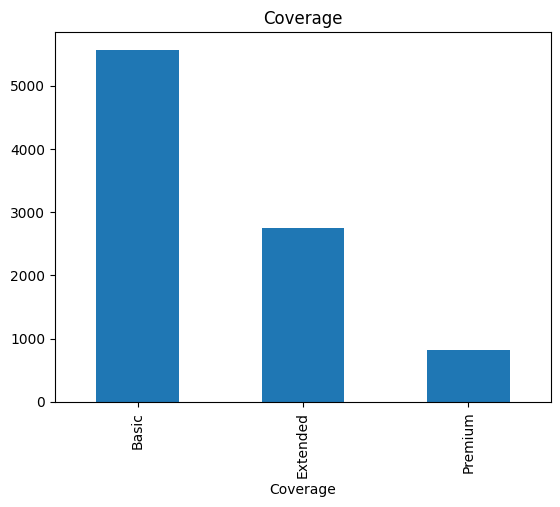

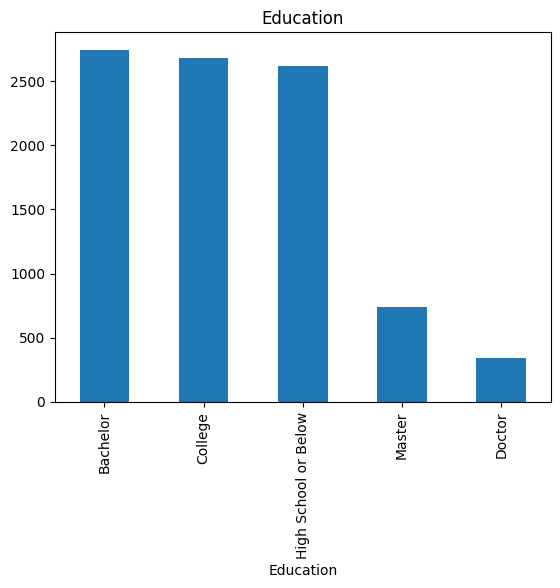

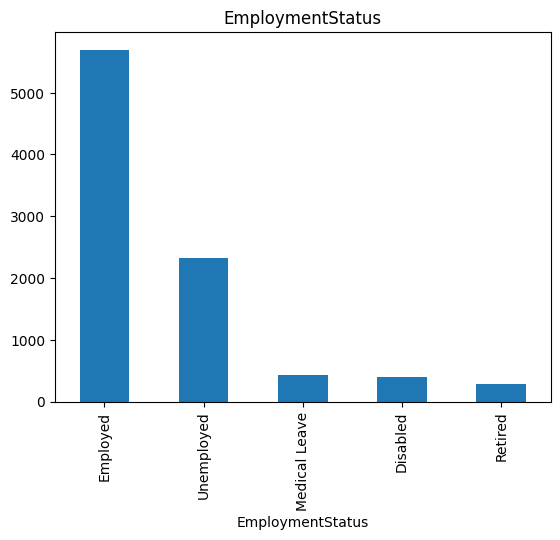

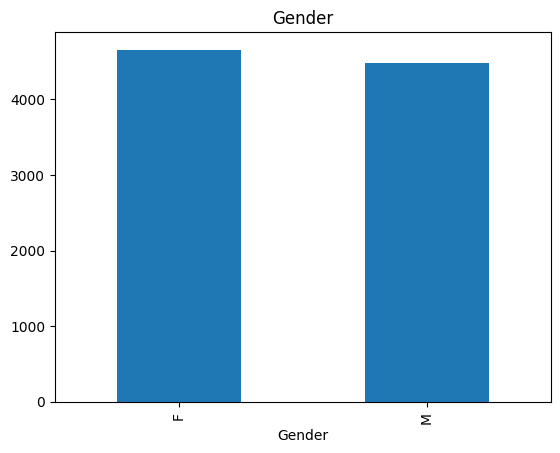

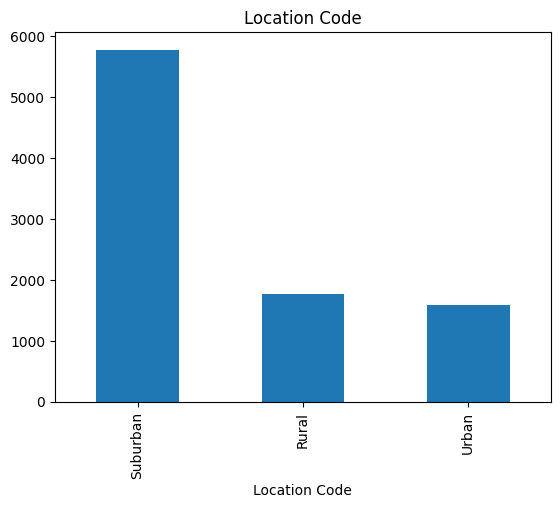

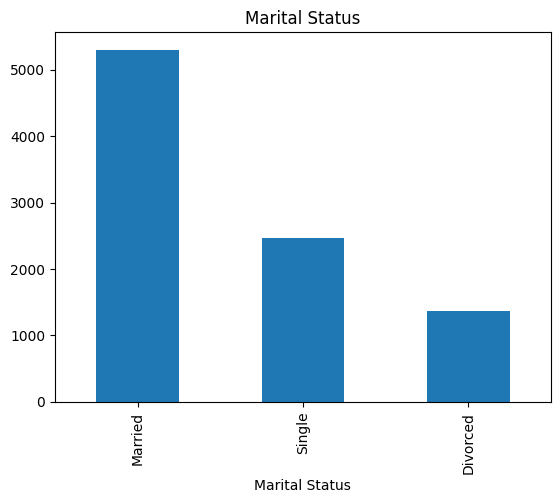

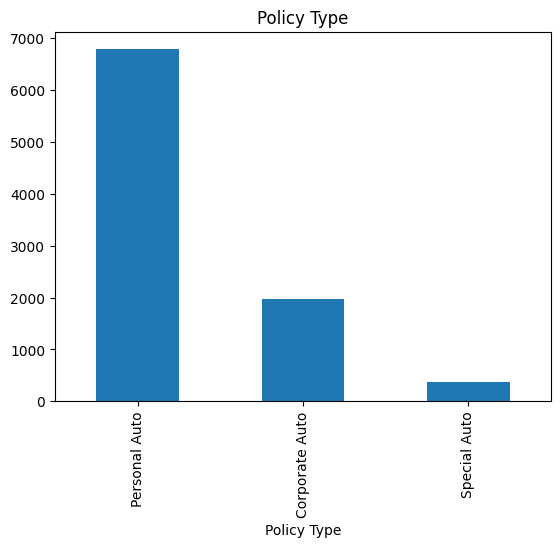

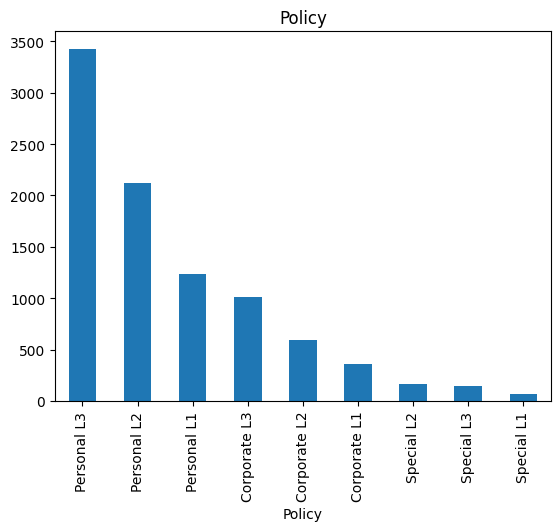

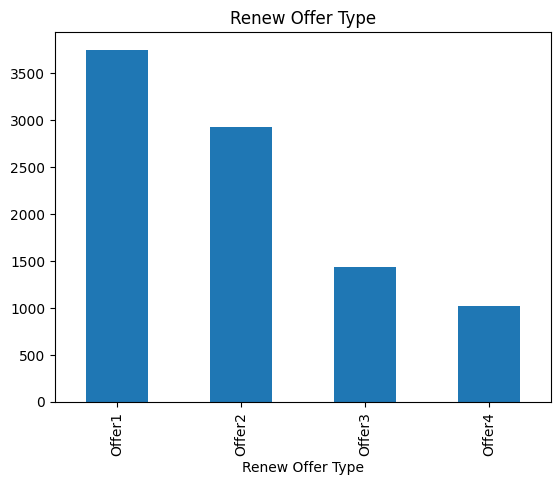

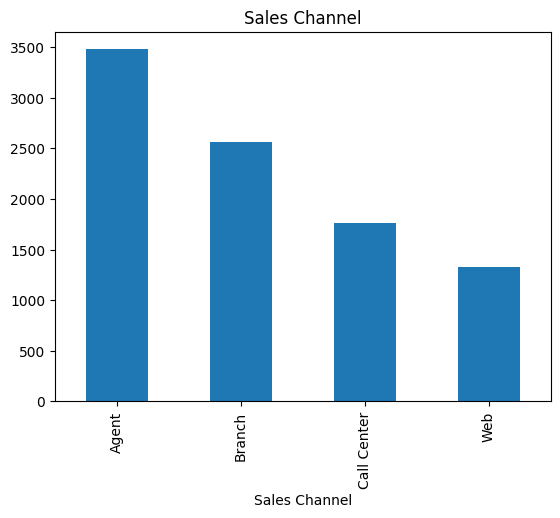

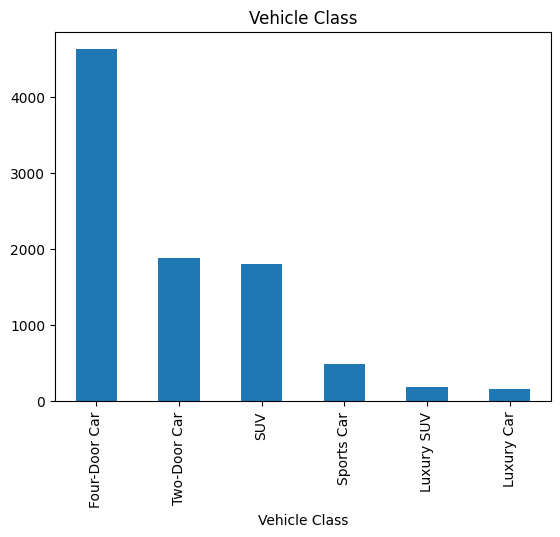

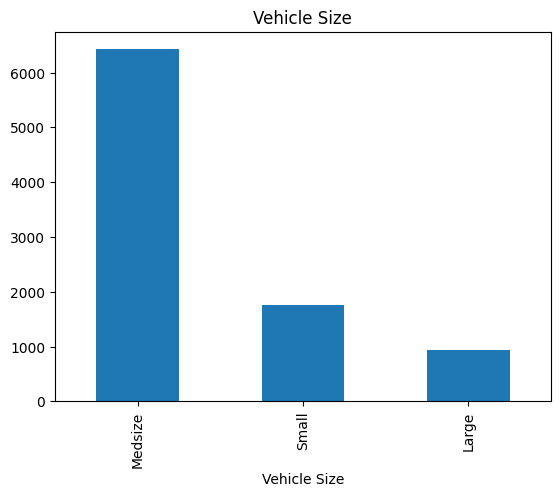

In [54]:
cat_cols = ['State', 'Response', 'Coverage', 'Education', 
       'EmploymentStatus', 'Gender', 'Location Code', 'Marital Status',
       'Policy Type', 'Policy', 'Renew Offer Type', 'Sales Channel',
       'Vehicle Class', 'Vehicle Size']
for i,cat in enumerate(df[cat_cols]):
    fig, ax = plt.subplots(1, 1)
    df[cat].value_counts().plot(kind = "bar").set_title(cat)
    fig.show()


Часть 2. Preprocessing & Feature Engineering

Хотя цель этого задания - посмотреть на работу алгоритмов, тем не менее пропускать препроцессинг нельзя :)

Так что переведите категориальные переменные в уникальные лейблы при помощи LabelEncoder, попробуйте добавить новые переменные и выкинуть лишние и, наконец, разбейте данные на train-test.

In [55]:
Y = df['Customer Lifetime Value']
X = df[df.columns.drop(['Customer Lifetime Value','Customer', 'Effective To Date'])] 
X.columns

Index(['State', 'Response', 'Coverage', 'Education', 'EmploymentStatus',
       'Gender', 'Income', 'Location Code', 'Marital Status',
       'Monthly Premium Auto', 'Months Since Last Claim',
       'Months Since Policy Inception', 'Number of Open Complaints',
       'Number of Policies', 'Policy Type', 'Policy', 'Renew Offer Type',
       'Sales Channel', 'Total Claim Amount', 'Vehicle Class', 'Vehicle Size'],
      dtype='str')

In [56]:
from sklearn.preprocessing import OneHotEncoder

categorical_columns = X.select_dtypes(include=['object']).columns.tolist()
encoder = OneHotEncoder(sparse_output=False)
one_hot_encoded = encoder.fit_transform(df[categorical_columns])
one_hot_df = pd.DataFrame(one_hot_encoded, columns=encoder.get_feature_names_out(categorical_columns))

df_encoded = pd.concat([X, one_hot_df], axis=1)

X = df_encoded.drop(categorical_columns, axis=1)


X.head()

/tmp/ipykernel_13877/2910743423.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=['object']).columns.tolist()


,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount,State_Arizona,State_California,State_Nevada,...,Sales Channel_Web,Vehicle Class_Four-Door Car,Vehicle Class_Luxury Car,Vehicle Class_Luxury SUV,Vehicle Class_SUV,Vehicle Class_Sports Car,Vehicle Class_Two-Door Car,Vehicle Size_Large,Vehicle Size_Medsize,Vehicle Size_Small
0,56274,69,32,5,0,1,384.811147,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0,94,13,42,0,8,1131.464935,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,48767,108,18,38,0,2,566.472247,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,0,106,18,65,0,7,529.881344,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,43836,73,12,44,0,1,138.130879,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [57]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

Часть 3. Who's the mightiest of them all?

Постройте 4 варианта градиентного бустинга, используя значения гиперпараметров “из коробки”: реализация из sklearn, XGBoost, CatBoost, LightGBM
Проверьте качество на отложенной выборке, кто пока лидирует?
Теперь проведите настройку гиперпараметров моделей на кросс-валидации, можно настраивать только самые основные гиперпараметры - число итераций бустинга, max_features, subsample и т.д.
Снова проверьте качество уже настроенных моделей. Кто в итоге победил?

In [58]:
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import *
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

In [59]:
def solve_metrics(func, func_name, x_train, y_train, x_test, y_test):
    func.fit(x_train, y_train)
    y_pred = func.predict(x_test)
    print(f"{func_name} - Mean Absolute Error:", mean_absolute_error(y_test.to_numpy(), y_pred))
    print(f"{func_name} - Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test.to_numpy(), y_pred)))
    return


In [60]:
gbclf = GradientBoostingRegressor()
solve_metrics(gbclf, "Gradient Boosting Regressor", X_train, Y_train, X_test, Y_test)

Gradient Boosting Regressor - Mean Absolute Error: 1738.5609274278788
Gradient Boosting Regressor - Root Mean Squared Error: 4127.306529164399


In [61]:
xgbr = XGBRegressor()
solve_metrics(xgbr, "XGB Regressor", X_train, Y_train, X_test, Y_test)

XGB Regressor - Mean Absolute Error: 1904.043960009303
XGB Regressor - Root Mean Squared Error: 4237.108266841592


In [62]:
lgbmr = LGBMRegressor()
solve_metrics(lgbmr, "LGBM Regressor", X_train, Y_train, X_test, Y_test)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000537 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 935
[LightGBM] [Info] Number of data points in the train set: 7307, number of used features: 64
[LightGBM] [Info] Start training from score 8022.789386
LGBM Regressor - Mean Absolute Error: 1567.1535407333167
LGBM Regressor - Root Mean Squared Error: 4016.2961176969848


In [63]:
cbr = CatBoostRegressor()
solve_metrics(cbr, "CatBoost Regressor", X_train, Y_train, X_test, Y_test)

Learning rate set to 0.05606
0:	learn: 6545.5428918	total: 3.13ms	remaining: 3.13s
1:	learn: 6321.3920721	total: 6.13ms	remaining: 3.06s
2:	learn: 6106.1076069	total: 9.03ms	remaining: 3s
3:	learn: 5908.4732064	total: 12.1ms	remaining: 3s
4:	learn: 5727.6323495	total: 14.7ms	remaining: 2.93s
5:	learn: 5562.1020241	total: 17.9ms	remaining: 2.97s
6:	learn: 5409.2609228	total: 20.5ms	remaining: 2.91s
7:	learn: 5267.5106925	total: 23.6ms	remaining: 2.93s
8:	learn: 5140.9204935	total: 26.5ms	remaining: 2.92s
9:	learn: 5018.6940769	total: 29.3ms	remaining: 2.9s
10:	learn: 4913.0079241	total: 32.2ms	remaining: 2.9s
11:	learn: 4807.4321808	total: 35.3ms	remaining: 2.91s
12:	learn: 4714.7569182	total: 38.9ms	remaining: 2.95s
13:	learn: 4629.1090309	total: 41.9ms	remaining: 2.95s
14:	learn: 4548.5643921	total: 44.3ms	remaining: 2.91s
15:	learn: 4473.7585542	total: 47.1ms	remaining: 2.9s
16:	learn: 4411.1549794	total: 50ms	remaining: 2.89s
17:	learn: 4351.3820457	total: 53ms	remaining: 2.89s
18:	

Лучшие результаты:

LGBM Regressor - Root Mean Squared Error: 4016.2961176969848

LGBM Regressor - Mean Absolute Error: 1567.1535407333167



Подбор параметров деревьев

число итераций бустинга, max_features, subsample и т.д.

In [64]:
def plot_hyperparameters_tuning(func, params, xlabel, x_train, y_train, x_test, y_test):
    quals_train = []
    quals_test = []
    for param in params:
        model = func(param)
        model.fit(x_train, y_train)
        q_train = root_mean_squared_error(y_train.to_numpy(), model.predict(x_train))
        q_test = root_mean_squared_error(y_test.to_numpy(), model.predict(x_test))
        quals_train.append(q_train)
        quals_test.append(q_test)

    plt.figure(figsize=(8, 5))
    plt.plot(params, quals_train, marker='.', label='train')
    plt.plot(params, quals_test, marker='.', label='test')
    plt.xlabel(xlabel)
    plt.ylabel('RMSE')
    plt.legend()

    plt.show()
   
    return

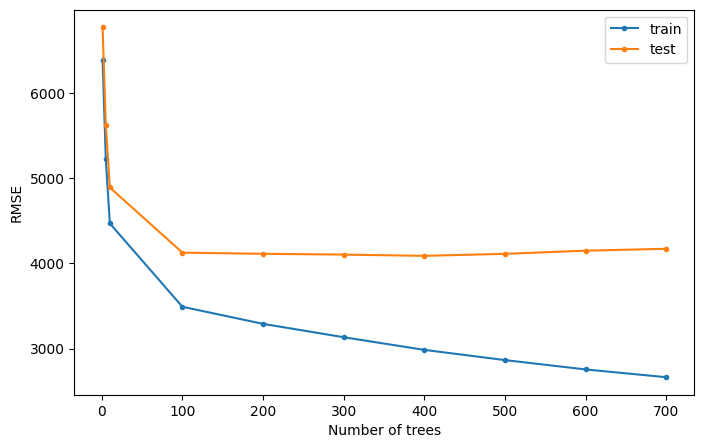

In [65]:
n_trees = [1, 5, 10, 100, 200, 300, 400, 500, 600, 700]

def gradient_boosting_regressor(n):
    return GradientBoostingRegressor(n_estimators = n)

plot_hyperparameters_tuning(gradient_boosting_regressor, n_trees, 'Number of trees', X_train, Y_train, X_test, Y_test)

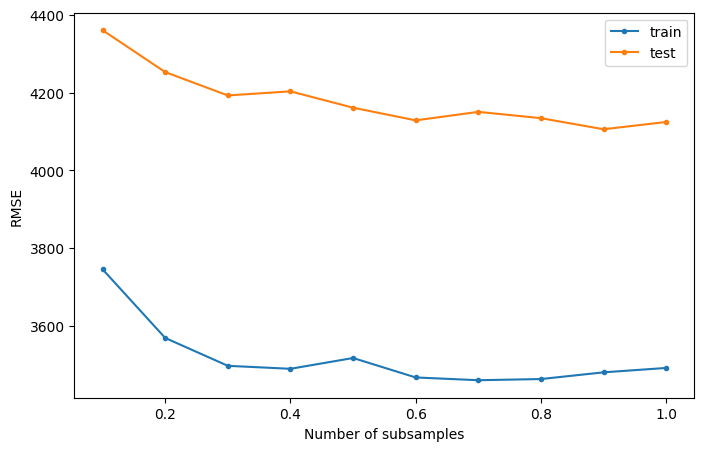

In [66]:
subsamples = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

def gradient_boosting_regressor(subsample):
    return GradientBoostingRegressor(subsample=subsample, n_estimators=100)

plot_hyperparameters_tuning(gradient_boosting_regressor, subsamples, 'Number of subsamples', X_train, Y_train, X_test, Y_test)

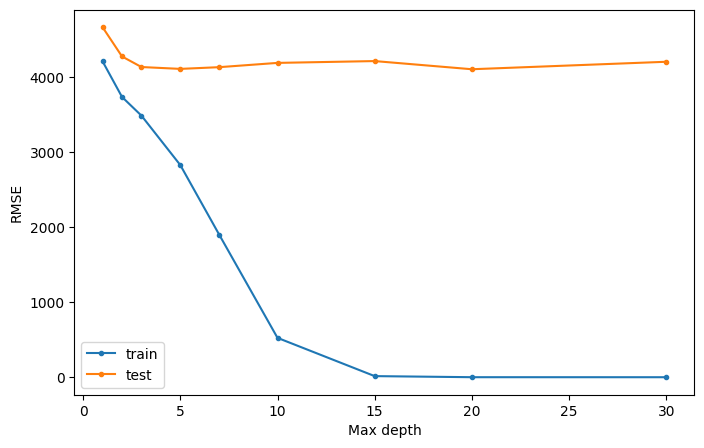

In [67]:
max_depths = [1, 2, 3, 5, 7, 10, 15, 20, 30]

def gradient_boosting_regressor(max_depth):
    return GradientBoostingRegressor(max_depth=max_depth, n_estimators= 100, subsample=0.9)

plot_hyperparameters_tuning(gradient_boosting_regressor, max_depths, 'Max depth', X_train, Y_train, X_test, Y_test)

In [68]:
gbclf = GradientBoostingRegressor(n_estimators= 100, subsample=0.9, max_depth = 20)

solve_metrics(gbclf, "Gradient Boosting Regressor", X_train, Y_train, X_test, Y_test)

Gradient Boosting Regressor - Mean Absolute Error: 1484.881515220823
Gradient Boosting Regressor - Root Mean Squared Error: 4192.568044579967


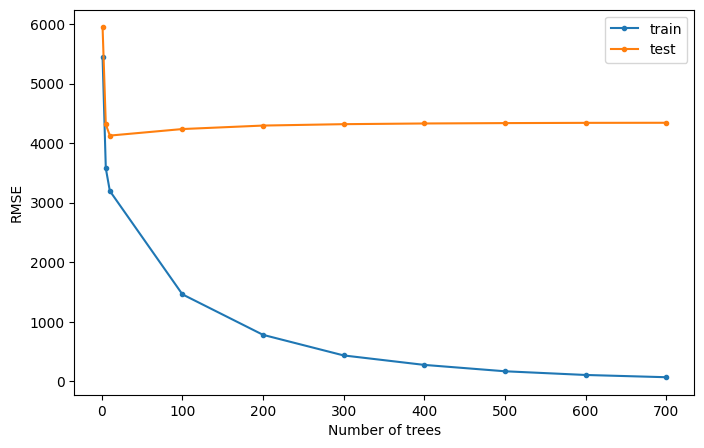

In [69]:
n_trees = [1, 5, 10, 100, 200, 300, 400, 500, 600, 700]

def xgboost_regressor(n):
    return XGBRegressor(n_estimators = n)

plot_hyperparameters_tuning(xgboost_regressor, n_trees, 'Number of trees', X_train, Y_train, X_test, Y_test)

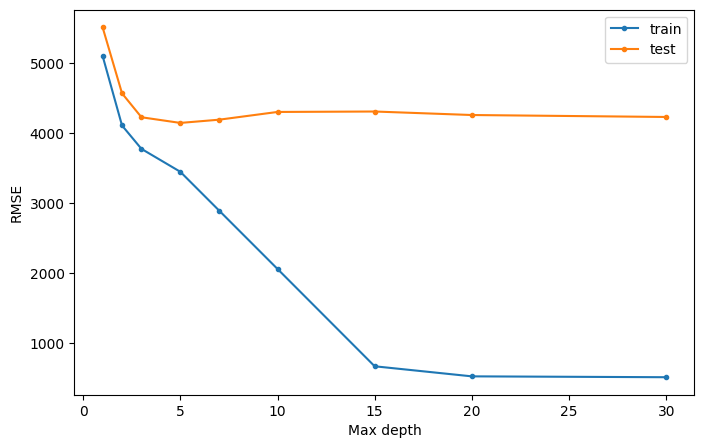

In [70]:
max_depths = [1, 2, 3, 5, 7, 10, 15, 20, 30]

def xgboost_regressor(max_depth):
    return XGBRegressor(max_depth=max_depth, n_estimators= 10)

plot_hyperparameters_tuning(xgboost_regressor, max_depths, 'Max depth', X_train, Y_train, X_test, Y_test)

In [71]:
xgbr = XGBRegressor(n_estimators= 10,  max_depth = 5)

solve_metrics(xgbr, "XGB Regressor", X_train, Y_train, X_test, Y_test)

XGB Regressor - Mean Absolute Error: 1667.5237913323583
XGB Regressor - Root Mean Squared Error: 4140.805090449409


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001078 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 935
[LightGBM] [Info] Number of data points in the train set: 7307, number of used features: 64
[LightGBM] [Info] Start training from score 8022.789386
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000534 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 935
[LightGBM] [Info] Number of data points in the train set: 7307, number of used features: 64
[LightGBM] [Info] Start training from score 8022.789386
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM]

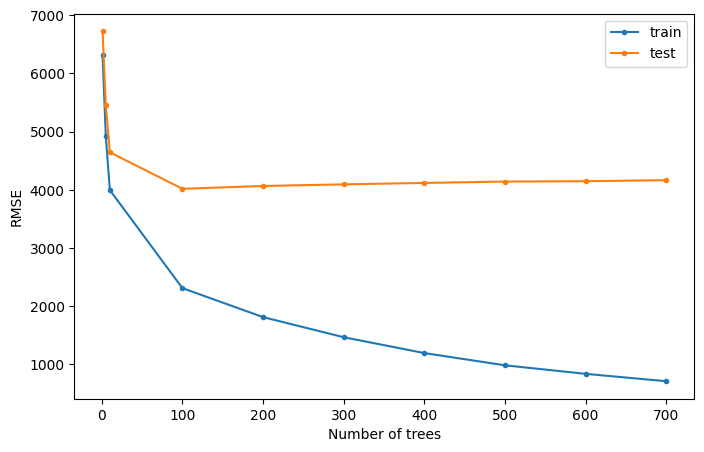

In [72]:
n_trees = [1, 5, 10, 100, 200, 300, 400, 500, 600, 700]

def lgbm_regressor(n_estimators):
    return LGBMRegressor(n_estimators=n_estimators)

plot_hyperparameters_tuning(lgbm_regressor, n_trees, 'Number of trees', X_train, Y_train, X_test, Y_test)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000619 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 935
[LightGBM] [Info] Number of data points in the train set: 7307, number of used features: 64
[LightGBM] [Info] Start training from score 8022.789386
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

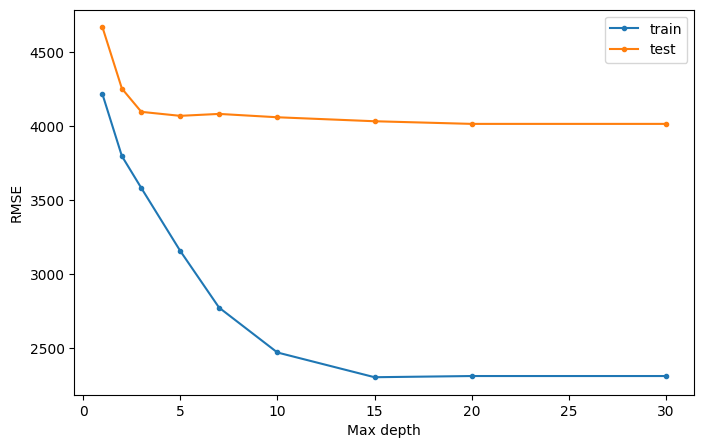

In [73]:
max_depths = [1, 2, 3, 5, 7, 10, 15, 20, 30]

def lgbm_regressor(max_depth):
    return LGBMRegressor(max_depth=max_depth, n_estimators= 100)

plot_hyperparameters_tuning(lgbm_regressor, max_depths, 'Max depth', X_train, Y_train, X_test, Y_test)

In [74]:
lgbmr = LGBMRegressor(n_estimators= 100,  max_depth = 15)

solve_metrics(lgbmr, "LGBM Regressor", X_train, Y_train, X_test, Y_test)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000698 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 935
[LightGBM] [Info] Number of data points in the train set: 7307, number of used features: 64
[LightGBM] [Info] Start training from score 8022.789386
LGBM Regressor - Mean Absolute Error: 1587.009223788471
LGBM Regressor - Root Mean Squared Error: 4034.1861002334854


Learning rate set to 0.5
0:	learn: 4840.5789873	total: 4.17ms	remaining: 0us
Learning rate set to 0.5
0:	learn: 4840.5789873	total: 3.35ms	remaining: 13.4ms
1:	learn: 4141.8945012	total: 7.22ms	remaining: 10.8ms
2:	learn: 3883.2937138	total: 10.4ms	remaining: 6.94ms
3:	learn: 3770.5866640	total: 13.6ms	remaining: 3.4ms
4:	learn: 3717.0724211	total: 16.5ms	remaining: 0us
Learning rate set to 0.5
0:	learn: 4840.5789873	total: 3.66ms	remaining: 33ms
1:	learn: 4141.8945012	total: 7.22ms	remaining: 28.9ms
2:	learn: 3883.2937138	total: 11.4ms	remaining: 26.5ms
3:	learn: 3770.5866640	total: 15.1ms	remaining: 22.7ms
4:	learn: 3717.0724211	total: 18.9ms	remaining: 18.9ms
5:	learn: 3688.5432985	total: 22.5ms	remaining: 15ms
6:	learn: 3671.2420502	total: 26ms	remaining: 11.1ms
7:	learn: 3642.9283313	total: 29.6ms	remaining: 7.41ms
8:	learn: 3595.6103788	total: 33ms	remaining: 3.67ms
9:	learn: 3570.2773459	total: 36.6ms	remaining: 0us
Learning rate set to 0.36446
0:	learn: 5303.5814559	total: 3.15

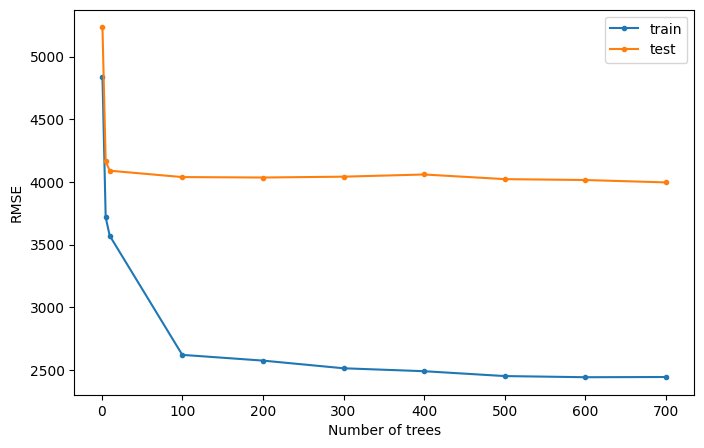

In [75]:
n_trees = [1, 5, 10, 100, 200, 300, 400, 500, 600, 700]

def catboost_regressor(n_estimators):
    return CatBoostRegressor(n_estimators=n_estimators)

plot_hyperparameters_tuning(catboost_regressor, n_trees, 'Number of trees', X_train, Y_train, X_test, Y_test)

Learning rate set to 0.149194
0:	learn: 6574.4951018	total: 1.52ms	remaining: 456ms
1:	learn: 6412.9992748	total: 2.98ms	remaining: 444ms
2:	learn: 6293.4706793	total: 4.37ms	remaining: 433ms
3:	learn: 6184.4517114	total: 5.74ms	remaining: 425ms
4:	learn: 6094.4672603	total: 7.06ms	remaining: 416ms
5:	learn: 6016.9810874	total: 8.44ms	remaining: 414ms
6:	learn: 5943.4680665	total: 10.2ms	remaining: 427ms
7:	learn: 5875.0559270	total: 11.7ms	remaining: 426ms
8:	learn: 5797.5852254	total: 12.5ms	remaining: 405ms
9:	learn: 5734.9614161	total: 14.2ms	remaining: 411ms
10:	learn: 5666.2869662	total: 15.4ms	remaining: 405ms
11:	learn: 5604.4644599	total: 16.8ms	remaining: 403ms
12:	learn: 5546.4802955	total: 18.2ms	remaining: 402ms
13:	learn: 5485.1024607	total: 19.6ms	remaining: 401ms
14:	learn: 5432.4746649	total: 21ms	remaining: 399ms
15:	learn: 5379.0916840	total: 22.3ms	remaining: 397ms
16:	learn: 5324.1299776	total: 23.9ms	remaining: 397ms
17:	learn: 5275.9333762	total: 25.4ms	remaining

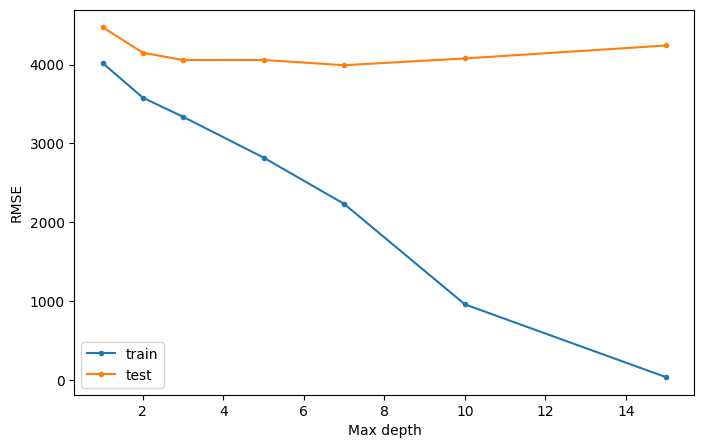

In [76]:
max_depths = [1, 2, 3, 5, 7, 10, 15]

def catboost_regressor(max_depth):
    return CatBoostRegressor(max_depth=max_depth, n_estimators= 300)

plot_hyperparameters_tuning(catboost_regressor, max_depths, 'Max depth', X_train, Y_train, X_test, Y_test)

In [77]:
cbr = CatBoostRegressor(n_estimators= 300,  max_depth = 7)

solve_metrics(cbr, "CatBoost Regressor", X_train, Y_train, X_test, Y_test)

Learning rate set to 0.149194
0:	learn: 6156.9047740	total: 5.06ms	remaining: 1.51s
1:	learn: 5635.4225589	total: 10.5ms	remaining: 1.56s
2:	learn: 5217.5165322	total: 14.8ms	remaining: 1.47s
3:	learn: 4888.9319734	total: 19.3ms	remaining: 1.43s
4:	learn: 4628.4869633	total: 23.2ms	remaining: 1.37s
5:	learn: 4417.1525020	total: 27.4ms	remaining: 1.34s
6:	learn: 4259.3764063	total: 31.5ms	remaining: 1.32s
7:	learn: 4120.9083460	total: 36ms	remaining: 1.31s
8:	learn: 4021.3632075	total: 41.3ms	remaining: 1.33s
9:	learn: 3940.8652126	total: 45.5ms	remaining: 1.32s
10:	learn: 3855.7125102	total: 50.1ms	remaining: 1.31s
11:	learn: 3797.2866016	total: 54.1ms	remaining: 1.3s
12:	learn: 3741.4852619	total: 58.1ms	remaining: 1.28s
13:	learn: 3694.8642845	total: 62.2ms	remaining: 1.27s
14:	learn: 3658.6261487	total: 66.4ms	remaining: 1.26s
15:	learn: 3627.0390919	total: 70.7ms	remaining: 1.25s
16:	learn: 3599.8133678	total: 74.9ms	remaining: 1.25s
17:	learn: 3578.0640894	total: 79.8ms	remaining:

### Лучший результат:

CatBoost Regressor - Root Mean Squared Error: 3992.9653206878606

Без настройки гиперпараметров CatBoost Regressor - Root Mean Squared Error: 4045.8429518232774